## MCP


### 1. 什么 MCP？
MCP（Model Context Protocol）是由 Anthropic 推出的开放标准，用于便捷的将AI应用连接外部系统

> 一句话理解：MCP 是「AI 应用的 USB-C 接口」



详细的MCP说明可以参考Anthropic公司的MCP官方文档：

https://modelcontextprotocol.io/docs/getting-started/intro

有关通信协议可以查看：

https://modelcontextprotocol.io/specification/2025-11-25/basic/transports

#### 1.1 为什么需要 MCP？

大模型本身不会查日历、发邮件、读数据库，这些能力必须靠定义工具实现。
- 在 MCP 出现之前，每接入一个新工具，每个 AI 应用都要单独写一套对接代码，复用性很差；
- 有了 MCP 之后，外部提供者都可以提供遵循 MCP 协议的服务，分享自己的 Tool，AI应用可以基于 MCP 协议调用并使用这些 Tool，无需自己定义

![image.png](attachment:743cf801-50d6-4cf9-9308-289394059123.png)

#### 1.2 MCP 三个核心概念

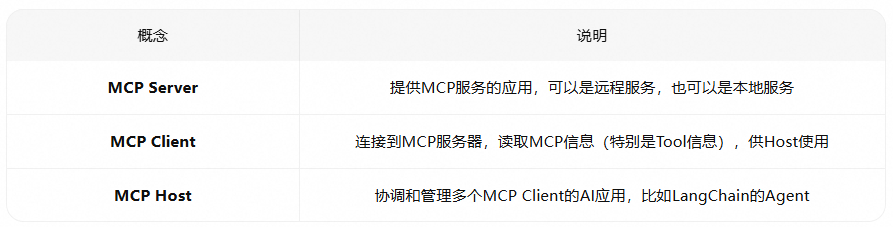
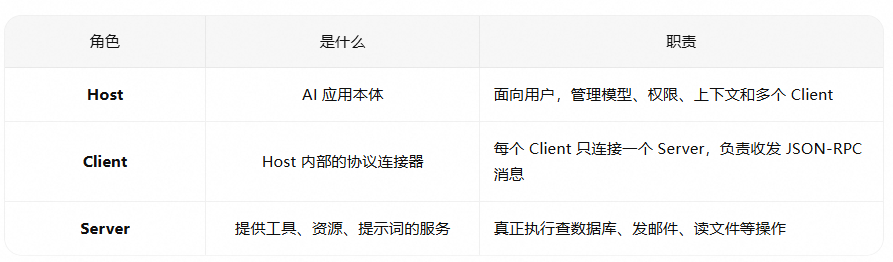
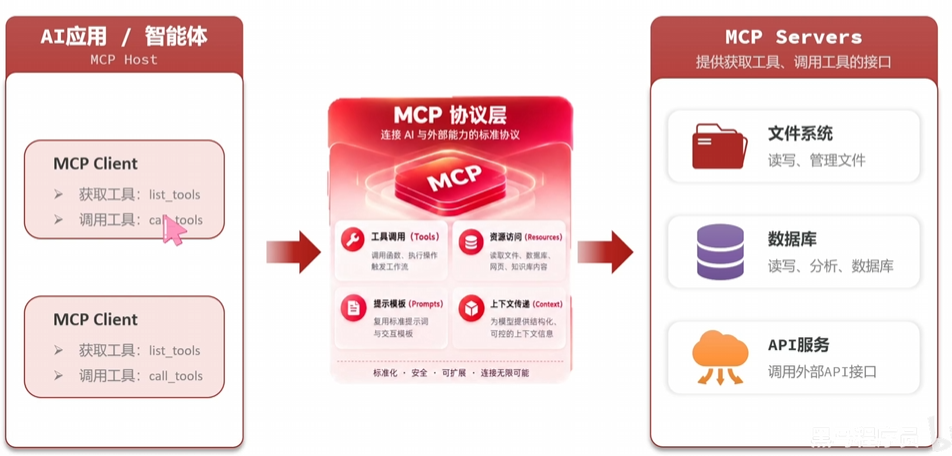
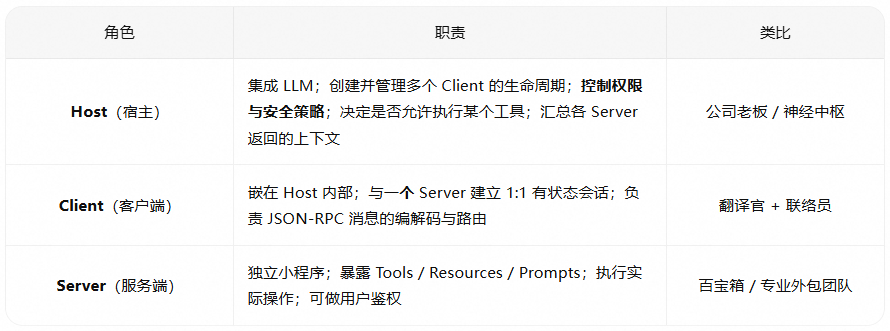

#### 1.3 MCP 两种通讯方式


```stdio```

stdio就是标准输入输出，MCP Client运行时，分两种情况：
- 外部服务：Client会把这个MCP服务的脚本下载到本地，然后作为一个子进程运行。
- 本地服务：Client会把本地脚本直接加载，作为一个子进程运行

也就是说，stdio模式中，MCP Client 和 MCP Server之间的通信就是进程通信，没有网络延迟。

```streamable_http```

streamable_http其实就是可以用event stream来发送数据的http模式，本质还是Server Send Event，也就是SSE。也就是说MCP client通过发送http请求与MCP server交互。因此存在一定的网络延迟。

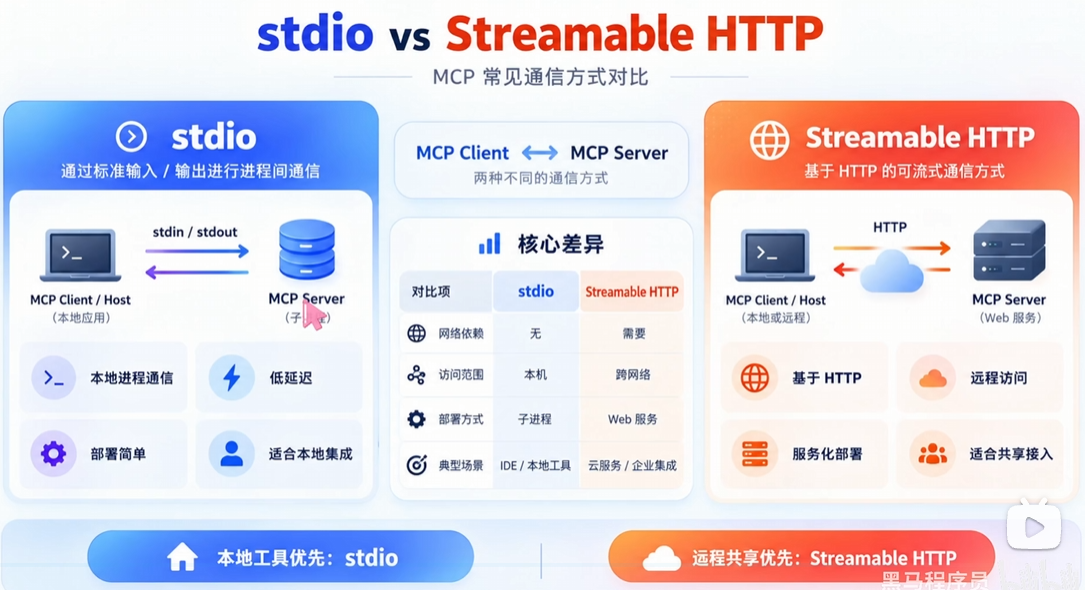

### 2. 连接外部 MCP 服务

很多提供云服务的公司都提供了MCP服务，例如：
- Amap Maps : 高德地图提供的MCP
- Filesystem : 可以操作文件系统的MCP
- Time : 查询当前时间的MCP服务
- Kiwi : 查询航班、预定航班的MCP服务
- ...

大家可以在 mcp.so 中搜索各种MCP服务（国际的比较多）：

https://mcp.so/zh/

也可以在魔塔社区搜索MCP服务（国产的比较多）：

https://modelscope.cn/mcp

也可以在魔塔社区搜索MCP服务（国产的比较多）：

找好自己想要使用的MCP服务后，就可以用LangChain来对接了。

首先，我们需要安装 LangChain 的 `MCP client` 依赖库:

```
uv add langchain-mcp-adapters # MCP client
```

接下来，就可以用LangChain对接MCP服务，获取其提供的工具，创建Agent了。

接下来，我们以两个MCP服务为例来介绍LangChain对接MCP服务的方式：
- Time MCP ：基于stdio通信
- Kiwi MCP : 基于Streamable http通信

#### 2.1 Time MCP服务（stdio）

Time是一个提供时间和时区转换功能的MCP服务。此服务使LLM能够获取当前时间信息，并使用 IANA 时区名称执行时区转换，同时具备自动检测系统时区的功能。

查看Time MCP的介绍页面，可以看到其介绍，以及集成方式：

https://mcp.so/zh/servers/time

需要注意的是，Time MCP是基于stdio的通信方式，也就是把这个MCP服务的脚本下载到本地，然后作为一个子进程运行。

其中，MCP脚本下载的方式取决于配置中的command，常见的有两种：
- npx : 基于node.js的包管理工具
- uvx : 基于uv(python的uv工具)的包管理工具

因此，你的本地环境必须支持npx、uvx命令

另外，在LangChain中除了基本的服务器配置，还必须设置一个transport参数，指定MCP服务的通信方式，有两个可选值：
- stdio
- http或者streamable_http

![image.png](attachment:0299fe5c-abf6-448a-aa29-caa96325c2f3.png)

In [7]:
# notebook 中跑不了
from langchain_mcp_adapters.client import MultiServerMCPClient

client = MultiServerMCPClient(
    {
        "time": {
            "transport": "stdio",
            "command": "uvx",
            "args":[
                "mcp-server-time",
                "--local-timezone=Asia/Shanghai"
            ]
        }
    }
)

tools = await client.get_tools()

UnsupportedOperation: fileno

for tool in tools:
    print

#### 2.2 Kiwi MCP服务（Streamable http）

Kiwi Travel MCP 将 [Kiwi.com](https://www.kiwi.com/en/) 的航班搜索功能直接引入到 AI 对话中。支持单程/往返、灵活日期、多名乘客以及所有舱位等级。

> 注意：
> - Kiwi 服务是基于 http 的通信方式，也就是说 MCP client 通过发送 http 请求与 MCP server 交互，在国内访问存在较大网络延迟。
> - 通常这类外部的 MCP 服务都是需要收费的，需要申请 API key 才能使用，而 Kiwi 是仅有的免费航班搜索服务

查看Kiwi介绍页，可以找到它的使用方式：

In [8]:
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain.agents import create_agent
from langchain_core.messages import HumanMessage

# 连接Kiwi MCP服务器
client = MultiServerMCPClient(
    {
        "kiwi-com-flight-search": {
            "transport": "http",
            "url": "https://mcp.kiwi.com"
        }
    }
)

# 注意MultiServerMCPClient是异步的，结果都是协程对象，需要await
tools = await client.get_tools()


agent = create_agent(
    model="deepseek-chat",
    tools=tools,
    system_prompt="You are a travel agent. Help user find best flights. No follow up questions. If the user uses Chinese, use zh-cn as the locale value."
)

response = await agent.ainvoke({
    "messages": [HumanMessage("查一下2026年5月15日晚上从北京飞杭州的航班。")]
})

for message in response["messages"]:
    message.pretty_print()

================================ Human Message =================================

查一下2026年5月15日晚上从北京飞杭州的航班。
================================== Ai Message ==================================
Tool Calls:
  search-flight (call_00_ROVGBNZX49ki2L9pzerd3291)
 Call ID: call_00_ROVGBNZX49ki2L9pzerd3291
  Args:
    flyFrom: 北京
    flyTo: 杭州
    departureDate: 15/05/2026
    dtime_from: 17
    dtime_to: 23
    locale: zh-cn
    currency: CNY
================================= Tool Message =================================
Name: search-flight

[{'type': 'text', 'text': '{\n  "query": "北京 → 杭州 on 15/05/2026, 1 adult [dep 17:00–23:00]",\n  "currency": null,\n  "passengers": null,\n  "resultsCount": 0,\n  "itineraries": [],\n  "searchTimeMs": 0,\n  "error": "These dates are in the past: departureDate (15/05/2026). Today is 05/11/2026 — please use dates today or later."\n}', 'id': 'lc_54db23a4-0996-4b39-aafc-5bd0e2172568'}]
================================== Ai Message =================================

> 注意：由于Kiwi中有地域参数（locale），但Tool描述中没说清楚，中文有两种：zh-cn,zh-tw，需要在系统提示词中说明，否则AI默认会传入zh，导致报错。

另外，有一个替代的国内航班查询MCP服务，地址是：https://mcp.variflight.com/

不过这个服务是收费的，而且价格比较贵，即便是优惠过后也需要0.1元/次。

使用步骤是：
- 注册账号
- 申请API Key
- 接入MCP
代码示例：

In [9]:
from langchain_mcp_adapters.client import MultiServerMCPClient

# 连接Kiwi MCP服务器
client = MultiServerMCPClient(
    {
        "VariFlight-Aviation": {
            "transport": "http",
            "url": "https://ai.variflight.com/servers/aviation/mcp/?api_key=您在飞友AI开放平台申请的Key"
        }
    }
)

tools = await client.get_tools()

agent = create_agent(
    model="deepseek-chat",
    tools=tools,
    system_prompt="You are a travel agent. Help user find best flights. No follow up questions."
)

response = await agent.ainvoke({
    "messages": [HumanMessage("查一下2026年5月15日晚上从北京飞杭州的航班。")]
})

for message in response["messages"]:
    message.pretty_print()

  + Exception Group Traceback (most recent call last):
  |   File "E:\Agent\L2阶段\langchain_tutorial\.venv\Lib\site-packages\IPython\core\interactiveshell.py", line 3821, in run_code
  |     await eval(code_obj, self.user_global_ns, self.user_ns)
  |   File "C:\Users\user\AppData\Local\Temp\ipykernel_42540\414754760.py", line 13, in <module>
  |     tools = await client.get_tools()
  |             ^^^^^^^^^^^^^^^^^^^^^^^^
  |   File "E:\Agent\L2阶段\langchain_tutorial\.venv\Lib\site-packages\langchain_mcp_adapters\client.py", line 213, in get_tools
  |     tools_list = await asyncio.gather(*load_mcp_tool_tasks)
  |                  ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  |   File "E:\Agent\L2阶段\langchain_tutorial\.venv\Lib\site-packages\langchain_mcp_adapters\tools.py", line 590, in load_mcp_tools
  |     async with create_session(
  |                ^^^^^^^^^^^^^^^
  |   File "C:\Users\user\AppData\Roaming\uv\python\cpython-3.12-windows-x86_64-none\Lib\contextlib.py", line 231, in _

### 3. 自定义 MCP 服务

在公司内部，不同团队之间也可以把自己团队的服务开发成MCP Server，供其它团队使用。

接下来，我们就学习如何自定义MCP服务。

#### 3.1 创建简单的MCP服务器
自定义MCP最简单的方式就是使用 `FastMCP` 了。

首先，需要安装依赖：
```
uv add fastmcp
```

接着，只需要定义几个方法，然后利用FastMCP提供的装饰器即可：
- @mcp.tool : 作为MCP中的工具
- @mcp.resources : 返回MCP需要的resources，类似拓展知识库
- @mcp.prompt : 返回MCP预定义的Prompt，预设的提示词

> 说明：MCP server端不仅可以提供tool，还可以提供resource、prompt，但通常不太常用，一般只需要提供tool即可。

通常我们只需要定义带有tool的MCP Server就可以了。

例如，我们定义一个数学运算的MCP服务，这个需要写到单独的py文件中，比如math_mcp_server.py：

In [3]:
# 代码见03-math_mcp_server.py

一个自定义MCP server就准备好了。

注意，由于我们是采用stdio方式，因此这个文件写好放在那里，不需要启动，将来MCP Client会自己启动并加载为子进程。

#### 3.2 连接接自定义MCP服务
由于我们自定义的MCP是本地py文件，所以启动的Command直接就是python，而不是npx或uvx

In [2]:
# 代码见04-math_mcp_client.py

### 4. 总结

1. **MCP是什么**
  - 开放协议，标准化LLM应用获取工具的方式
  - 客户端-服务器架构
2. **连接方式**
  - STDIO: 本地MCP服务器
  - HTTP: 远程MCP服务器
3. **使用流程**
  - 配置MultiServerMCPClient
  - 调用get_tools()获取工具
  - 创建Agent并调用
4. **自定义MCP Server**
  - 导入FastMCP
  - 使用@mcp.tool装饰函数，定义工具（必备）
  - 使用@mcp.resource装饰函数，返回resources（可选）
  - 使用@mcp.prompt装饰函数，返回Prompt（可选）
  - 使用mcp.run()启动MCP服务